Saving Train_data.csv to Train_data (5).csv
Dataset Loaded!
   duration protocol_type   service flag  src_bytes  dst_bytes  land  \
0         0           tcp  ftp_data   SF        491          0     0   
1         0           udp     other   SF        146          0     0   
2         0           tcp   private   S0          0          0     0   
3         0           tcp      http   SF        232       8153     0   
4         0           tcp      http   SF        199        420     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                  25   
1               0       0    0  ...                   1   
2               0       0    0  ...                  26   
3               0       0    0  ...                 255   
4               0       0    0  ...                 255   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                    0.17                    0.03   
1                    0.00                    0

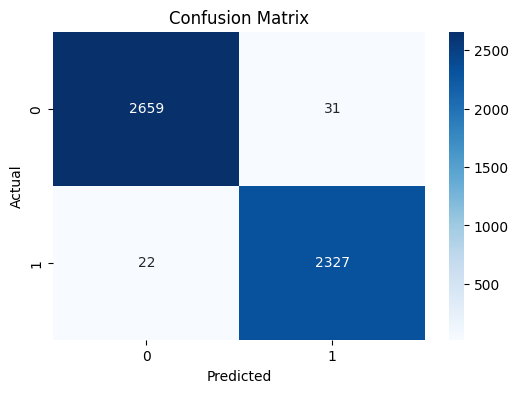

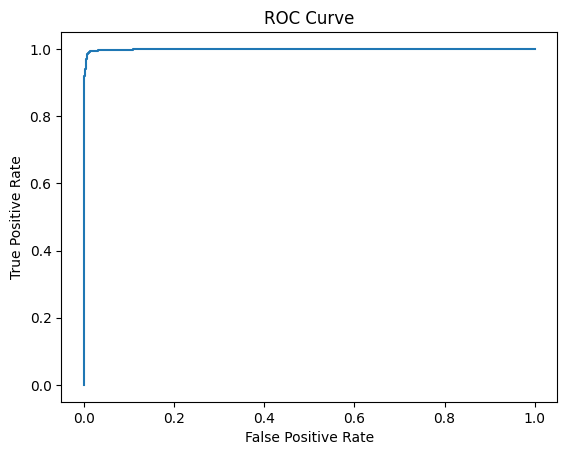

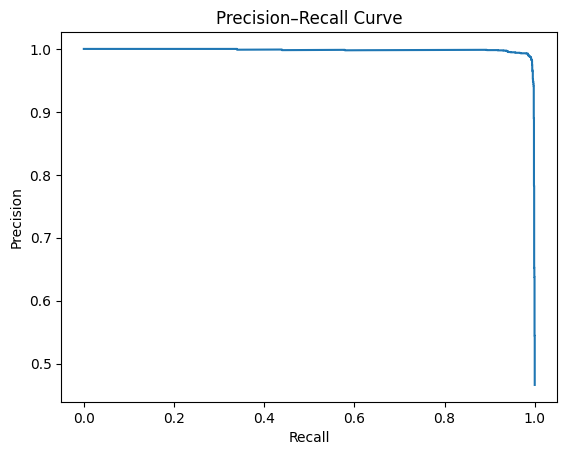


All tasks completed successfully!


In [10]:
# ============================================================
# 1. Upload dataset
# ============================================================
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

data = pd.read_csv("Train_data.csv")  # change if filename differs
print("Dataset Loaded!")
print(data.head())


# ============================================================
# 2. Identify Categorical Columns
# ============================================================
categorical_cols = ["protocol_type", "service", "flag"]
label_column = "class"

print("\nCategorical Columns:", categorical_cols)


# ============================================================
# 3. One-Hot Encode Categorical Features
# ============================================================
data_encoded = pd.get_dummies(data, columns=categorical_cols)

print("\nAfter Encoding:", data_encoded.shape)


# ============================================================
# 4. Create X and y
# ============================================================
X = data_encoded.drop(columns=[label_column])
y = data_encoded[label_column]

# Convert labels to binary: anomaly=1, normal=0
y = (y == "anomaly").astype(int)


# ============================================================
# 5. Train/Test Split (80/20)
# ============================================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nData Split Complete!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


# ============================================================
# 6. SCALE DATA (ESSENTIAL for SVM)
# ============================================================
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling Complete.")


# ============================================================
# 7. Train SVM Model
# ============================================================
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

print("\nSVM Training Complete!")


# ============================================================
# 8. Predictions + Probabilities
# ============================================================
y_pred = svm_model.predict(X_test_scaled)
y_prob = svm_model.predict_proba(X_test_scaled)[:, 1]


# ============================================================
# 9. Evaluation Metrics
# ============================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

print("\n===== METRICS =====")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("AUROC:", roc_auc_score(y_test, y_prob))
print("AUPRC:", average_precision_score(y_test, y_prob))


# ============================================================
# 10. Confusion Matrix + Heatmap
# ============================================================
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ============================================================
# 11. ROC Curve
# ============================================================
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()


# ============================================================
# 12. Precision–Recall Curve
# ============================================================
from sklearn.metrics import precision_recall_curve

prec, rec, _ = precision_recall_curve(y_test, y_prob)

plt.plot(rec, prec)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.show()

print("\nAll tasks completed successfully!")
